# Collecter, nettoyer et stocker des posts Bluesky sur une entreprise

Que dit-on d'une entreprise sur les réseaux sociaux ? Cette démonstration suit les premières étapes d'un projet de *text mining* (fouille de textes), celles qui prennent le plus de temps dans un vrai projet data :

1. **collecter** des posts publics qui citent l'entreprise, sur le réseau social [Bluesky](https://bsky.app) ;
2. les **anonymiser**, dès la collecte ;
3. les **nettoyer**, pour ne garder que les mots qui portent du sens ;
4. les **stocker**, dans un fichier et dans une base de données ;
5. en tirer une première **vue métier** : de quoi parle-t-on, et quand ?

Dans la méthode CRISP-DM, ce sont la compréhension et la préparation des données.

Pour la lancer : *Exécution > Tout exécuter* dans Colab, *Run All* dans un Codespace. Si Bluesky ne répond pas, le notebook se rabat sur des posts synthétiques, écrits pour la démonstration avec le même bruit que de vrais posts. **Les sorties enregistrées dans ce notebook viennent de ces posts synthétiques** : en formation, la démonstration tourne en direct sur Bluesky.

## 0. Installation et paramètres

La bibliothèque `wordcloud` dessine le nuage de mots de la fin (Colab l'a déjà).

In [1]:
!pip install -q --no-warn-script-location wordcloud

L'entreprise étudiée, la langue des posts et leur nombre. Changez `QUERY` pour étudier une autre entreprise : le reste du notebook suit. `LIVE = False` passe directement aux posts synthétiques, sans appeler Bluesky.

In [2]:
import hashlib
import re
import sqlite3
import time
import unicodedata
from collections import Counter
from itertools import pairwise

import matplotlib.pyplot as plt
import pandas as pd
import requests
import spacy
from wordcloud import WordCloud

QUERY = "Ikea"  # l'entreprise étudiée
LANG = "fr"  # la langue des posts
MAX_POSTS = 1000  # le nombre de posts à collecter
LIVE = True  # False : les posts synthétiques, sans appeler Bluesky

## 1. Collecter les posts

Bluesky est un réseau social ouvert : son API de recherche, la barre de recherche du site pour un programme, répond sans compte. On lui demande les posts les plus récents qui contiennent le nom de l'entreprise, par pages de 100, en remontant le temps, avec une pause d'une seconde entre deux pages pour ne pas surcharger le service.

In [3]:
API_URL = "https://api.bsky.app/xrpc/app.bsky.feed.searchPosts"


def search_posts(query, lang, max_posts):
  """Les posts les plus récents qui contiennent `query`, page par page."""
  posts = {}
  until = None
  while len(posts) < max_posts:
    params = {"q": query, "lang": lang, "sort": "latest", "limit": 100}
    if until:
      params["until"] = until  # la page suivante : les posts publiés avant
    response = requests.get(API_URL, params=params, timeout=30)
    response.raise_for_status()
    page = response.json()["posts"]
    new = {post["uri"]: post for post in page if post["uri"] not in posts}
    if not new:
      break
    posts.update(new)
    until = min(post["indexedAt"] for post in page)
    time.sleep(1)  # délai de politesse entre deux requêtes
  return list(posts.values())[:max_posts]

**Anonymisation.** Un post est une donnée personnelle au sens du RGPD : son auteur est identifiable. Pour compter des mots, on n'a pas besoin de savoir qui parle. Dès la collecte, on ne garde donc ni le pseudonyme, ni l'identifiant, ni le nom affiché de l'auteur, et on masque dans le texte les mentions d'autres comptes (`@…`) : c'est le principe de minimisation, ne collecter que ce qui sert le projet.

Ce n'est qu'une pseudonymisation : le texte d'un post se retrouve par une simple recherche. Les données restent personnelles, donc à ne conserver que le temps du projet.

In [4]:
MENTION = re.compile(r"@[\w-]+(?:\.[\w-]+)*")  # @pseudo.bsky.social


def anonymize(post):
  """Le post sans son auteur : ni pseudonyme, ni identifiant, ni nom affiché."""
  return {
    # une clé pour repérer les doublons, illisible
    "post_id": hashlib.sha256(post["uri"].encode()).hexdigest()[:16],
    "created_at": post["record"]["createdAt"],
    "text": MENTION.sub("@anonyme", post["record"].get("text", "")),
    "likes": post.get("likeCount", 0),
    "reposts": post.get("repostCount", 0),
    "replies": post.get("replyCount", 0),
  }

La collecte. Si l'API ne répond pas, ou renvoie moins de 100 posts, on charge les posts synthétiques : des posts sur Ikea écrits pour la démonstration, mentions déjà masquées.

In [5]:
FALLBACK_URL = (
  "https://github.com/shuuchuu/datasets/raw/refs/heads/main/"
  f"bluesky-ikea-synthetic/posts-{LANG}.csv"
)
MIN_POSTS = 100

collected = []
if LIVE:
  try:
    collected = [anonymize(post) for post in search_posts(QUERY, LANG, MAX_POSTS)]
  except requests.RequestException as error:
    print(f"L'API de Bluesky ne répond pas ({error}).")

if len(collected) >= MIN_POSTS:
  posts = pd.DataFrame(collected)
  print(f"{len(posts)} posts collectés en direct sur Bluesky.")
else:
  posts = pd.read_csv(FALLBACK_URL)
  QUERY = "Ikea"  # l'entreprise des posts synthétiques
  print(
    f"{len(collected)} posts collectés en direct : on passe aux posts synthétiques."
  )
  print(f"{len(posts)} posts synthétiques sur Ikea, écrits pour la démonstration.")

posts["created_at"] = pd.to_datetime(
  posts["created_at"], utc=True, format="ISO8601", errors="coerce"
)
first, last = posts["created_at"].min(), posts["created_at"].max()
print(f"Du {first:%Y-%m-%d} au {last:%Y-%m-%d}.")
posts[["created_at", "text", "likes"]].head()

0 posts collectés en direct : on passe aux posts synthétiques.
416 posts synthétiques sur Ikea, écrits pour la démonstration.
Du 2026-08-20 au 2026-10-17.


,created_at,text,likes
0,2026-10-17 21:23:44.929000+00:00,"Le Kallax, c'est le meilleur rangement pour le...",5
1,2026-10-17 15:45:32.386000+00:00,🔥 PROMO 🔥 Meubles Ikea jusqu'à -50 % ! Liste d...,0
2,2026-10-17 13:48:27.935000+00:00,@anonyme Quelqu'un a déjà monté un Pax seul ? ...,0
3,2026-10-17 08:03:42.783000+00:00,🔥 PROMO 🔥 Meubles Ikea jusqu'à -50 % ! Liste d...,0
4,2026-10-17 07:09:41.773000+00:00,"Le Kallax, c'est le meilleur rangement pour le...",0


## 2. Nettoyer les textes

Pour l'ordinateur, un texte n'est qu'une suite de caractères. Pour compter les mots qui comptent, on le découpe en mots avec spaCy, une bibliothèque de traitement du langage qui sait que « l'entreprise » en fait deux, et on retire le bruit : liens, mentions, emojis, ponctuation, chiffres, et les mots vides (« le », « de », « et »), très fréquents mais sans contenu, ainsi que le nom de l'entreprise, présent partout. On passe tout en minuscules, pour que « Meuble » et « meuble » soient le même mot, et on garde le mot des hashtags (#cuisine devient cuisine).

In [6]:
nlp = spacy.blank(LANG)  # le découpage en mots de spaCy, pour la langue
STOP_WORDS = nlp.Defaults.stop_words  # et ses mots vides
URL = re.compile(r"https?://\S+|\b(?:[\w-]+\.)+[a-z]{2,}/\S*")


def strip_accents(word):
  return unicodedata.normalize("NFKD", word).encode("ascii", "ignore").decode()


# le nom de l'entreprise, avec ou sans accent (« ikéa »)
COMPANY = {strip_accents(word) for word in QUERY.lower().split()}


def clean(text):
  """Les mots d'un post qui portent du sens, en minuscules."""
  text = URL.sub(" ", text.lower())  # liens
  text = re.sub(r"@\S+", " ", text)  # mentions
  words = [
    token.text
    for token in nlp(text)
    if token.is_alpha  # ni emoji, ni ponctuation, ni chiffre, ni #
    and not token.is_stop
    and len(token) > 2
    and strip_accents(token.text) not in COMPANY
  ]
  return " ".join(words)


posts["clean_text"] = posts["text"].map(clean)

Avant et après, sur trois posts qui contiennent un lien, une mention ou un hashtag :

In [7]:
examples = posts[posts["text"].str.contains(r"[@#/]")].drop_duplicates("text").head(3)
for text, cleaned in zip(examples["text"], examples["clean_text"]):
  print(f"AVANT : {text}")
  print(f"APRÈS : {cleaned}")
  print()

AVANT : 🔥 PROMO 🔥 Meubles Ikea jusqu'à -50 % ! Liste des bons plans ici 👉 https://bit.ly/3xKpromo #ikea #bonplan
APRÈS : promo meubles liste bons plans ici bonplan

AVANT : @anonyme Quelqu'un a déjà monté un Pax seul ? Je suis à l'étape 12 et je doute de tout (déménagement en cours)
APRÈS : monté pax étape doute déménagement cours

AVANT : Real talk: the Kallax is the best storage for vinyl records, no debate #home
APRÈS : real talk the kallax the best storage for vinyl records debate home



On retire ensuite trois sortes de posts :

- ceux d'une autre langue : la langue que Bluesky donne à un post est celle des réglages de l'application de son auteur, pas toujours celle du post. On garde ceux qui ont au moins autant de mots vides de la langue étudiée que de l'autre ;
- ceux que le nettoyage a vidés (un lien seul, des emojis) ;
- les doublons : la recherche ne renvoie pas les reposts (les partages), mais des comptes automatiques publient plusieurs fois le même texte, qui gonflerait le compte de ses mots.

In [8]:
OTHER_STOP_WORDS = spacy.blank("en" if LANG == "fr" else "fr").Defaults.stop_words


def in_language(text):
  """Vrai si le post a au moins autant de mots vides de LANG que de l'autre langue."""
  words = re.findall(r"\w+", text.lower())
  own = sum(word in STOP_WORDS for word in words)
  return own >= sum(word in OTHER_STOP_WORDS for word in words)


collected = len(posts)
posts = posts[posts["text"].map(in_language)]
other_language = collected - len(posts)
posts = posts[posts["clean_text"] != ""]
empty = collected - other_language - len(posts)
posts = posts.drop_duplicates(subset="clean_text").reset_index(drop=True)
print(f"{collected} posts collectés")
print(f"- {other_language} dans une autre langue")
print(f"- {empty} vides après nettoyage")
print(f"- {collected - other_language - empty - len(posts)} doublons")
print(f"= {len(posts)} posts à analyser")

416 posts collectés
- 22 dans une autre langue
- 15 vides après nettoyage
- 52 doublons
= 327 posts à analyser


## 3. Stocker les données

Deux formats courants : un fichier CSV, qu'Excel ouvre et qui se partage facilement, et une base de données SQLite, qu'on interroge en SQL, le langage des bases de données. En entreprise, ces données iraient dans l'entrepôt ou le lac de données, avec la date de la collecte et la recherche faite, pour pouvoir refaire l'analyse.

In [9]:
posts.to_csv("posts.csv", index=False)

connection = sqlite3.connect("posts.db")
posts.to_sql("posts", connection, if_exists="replace", index=False)
pd.read_sql("SELECT COUNT(*) AS posts FROM posts", connection)

,posts
0,327


Une requête SQL : le nombre de posts et de « j'aime » par jour, sur les sept derniers jours de la collecte.

In [10]:
query = """
SELECT date(created_at) AS day, COUNT(*) AS posts, SUM(likes) AS likes
FROM posts
GROUP BY day
ORDER BY day DESC
LIMIT 7
"""
pd.read_sql(query, connection)

,day,posts,likes
0,2026-10-17,3,5
1,2026-10-16,3,1
2,2026-10-15,6,19
3,2026-10-14,6,12
4,2026-10-13,4,0
5,2026-10-12,2,0
6,2026-10-11,4,1


## 4. Une première vue métier

Les mots les plus fréquents disent de quoi l'on parle quand on parle de l'entreprise.

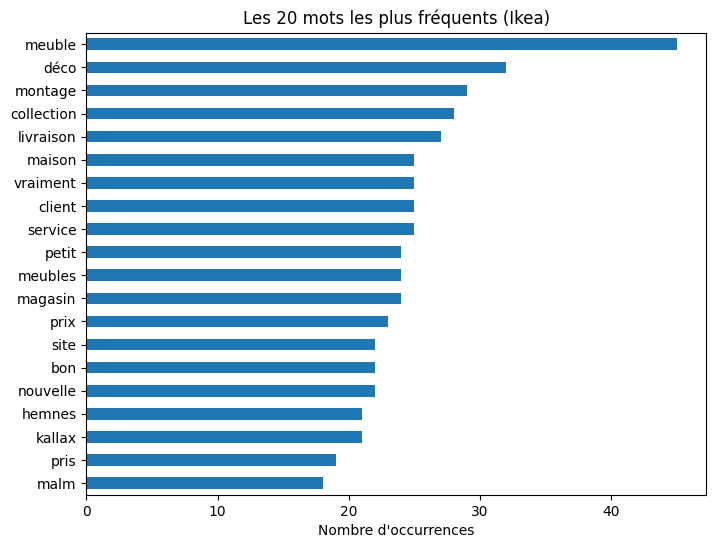

In [11]:
words = Counter(word for text in posts["clean_text"] for word in text.split())
top_words = pd.Series(dict(words.most_common(20))).sort_values()
top_words.plot.barh(figsize=(8, 6), title=f"Les 20 mots les plus fréquents ({QUERY})")
plt.xlabel("Nombre d'occurrences")
plt.show()

Les bigrammes, deux mots qui se suivent, donnent plus de contexte qu'un mot seul (« service client », « livraison retard »).

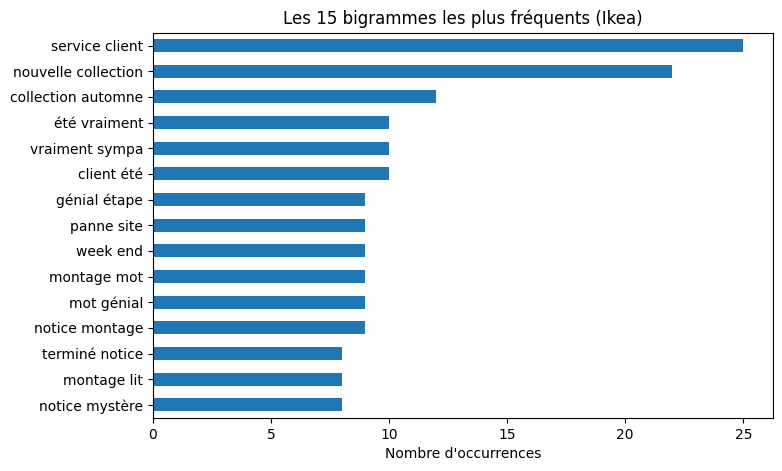

In [12]:
bigrams = Counter(
  f"{a} {b}" for text in posts["clean_text"] for a, b in pairwise(text.split())
)
top_bigrams = pd.Series(dict(bigrams.most_common(15))).sort_values()
top_bigrams.plot.barh(
  figsize=(8, 5), title=f"Les 15 bigrammes les plus fréquents ({QUERY})"
)
plt.xlabel("Nombre d'occurrences")
plt.show()

Le volume de posts par jour : un pic signale un événement à creuser (une annonce, une polémique, un rappel de produit).

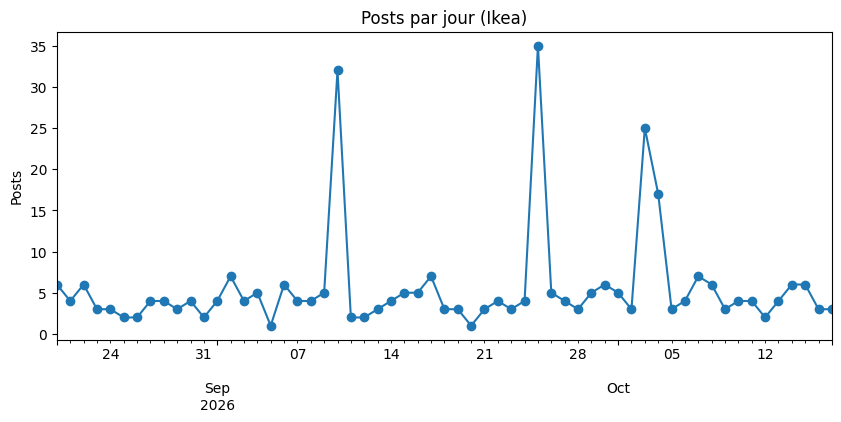

In [13]:
per_day = posts.set_index("created_at").resample("D").size()
per_day.plot(figsize=(10, 4), marker="o", title=f"Posts par jour ({QUERY})")
plt.xlabel("")
plt.ylabel("Posts")
plt.show()

Et un nuage de mots, où la taille d'un mot suit sa fréquence : moins précis qu'un graphique, mais parlant.

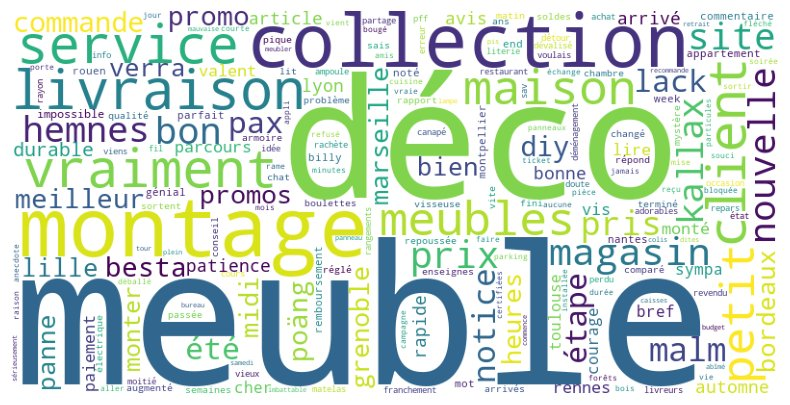

In [14]:
cloud = WordCloud(width=800, height=400, background_color="white")
cloud.generate_from_frequencies(words)
plt.figure(figsize=(10, 5))
plt.imshow(cloud)
plt.axis("off")
plt.show()

## Pour aller plus loin

- **Limites** : les utilisateurs de Bluesky ne sont pas les clients de l'entreprise, quelques centaines de posts récents ne sont qu'un échantillon, et un mot fréquent ne dit pas si l'avis est positif ou négatif.
- **Suite du projet** : analyse de sentiment, détection des thèmes, une liste de mots vides propre au projet (des mots courants comme « bien » ou « faire »), lemmatisation (« meuble » et « meubles » comptés ensemble), collecte quotidienne automatisée pour suivre l'évolution et lever des alertes.
- **RGPD** : une base légale (l'intérêt légitime, en général), une durée de conservation, l'information des personnes et leur droit d'opposition, à prévoir avant de collecter.